In [1]:
source('../../../R/preamble.R')

In [2]:
mutators = tribble(
    ~start, ~end, ~r, ~rend, ~bg,
    6, 6, 'F', 'F', 'mutS(G696E)',
    7, 7, 'E', 'E', 'mutL(Δ6)',
    8, 8, 'D', 'D', 'pMutS'
    )

reversions = tribble(
    ~start, ~end, ~r, ~rend, ~bg,
    14, 14, 'E', 'E', 'mutS(G696E)',
    18, 18, 'F', 'F', 'mutS(G696E)',
    16, 16, 'G', 'G', 'mutS(G696E)',
    20, 20, 'H', 'H', 'mutS(G696E)',
    )

pops = tribble(
    ~start, ~end, ~r, ~rend, ~bg, ~pop,
    24, 24, 'A', 'A', 'none', 'A',
    24, 24, 'B', 'B', 'none', 'B',
    24, 24, 'C', 'C', 'none', 'C',
    24, 24, 'D', 'D', 'none', 'D',
    24, 24, 'E', 'E', 'none', 'E',
    24, 24, 'F', 'F', 'none', 'F',
    24, 24, 'G', 'G', 'none', 'G',
    24, 24, 'H', 'H', 'none', 'H',
    12, 12, 'E', 'E', 'none', 'X',
    13, 13, 'G', 'G', 'none', 'Y',
    8, 8, 'H', 'H', 'none', 'Z'
    )

Warning message in geom_text(data = pops, aes(label = pop), fill = w, col = wt_color, :
“Ignoring unknown parameters: `fill`”


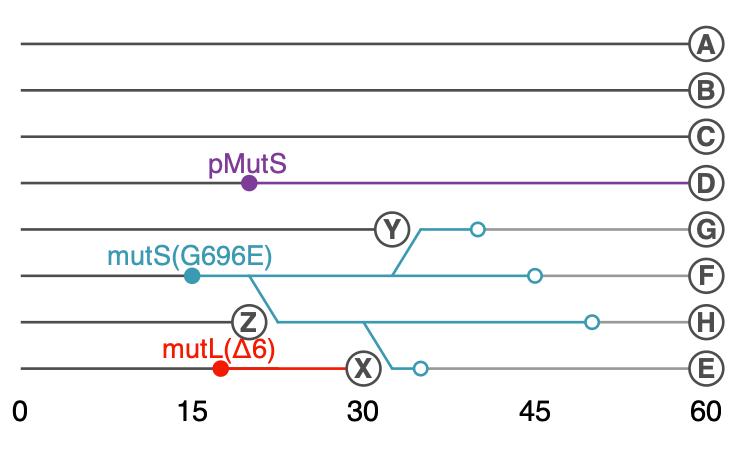

In [3]:
reactor_order = c('E', 'H', 'F', 'G', 'D', 'C', 'B', 'A')
discrete_pal = c('#3B9AB2', '#7D3C98', '#EBCC2A', '#95A5A6', '#F21A00', '#27AE60')

lwd = 0.3
text_size = 2.3
text_weight = 'plain'
ps = 1.2
pop_circle_size = 3.5
wt_color = 'grey30'

size(1.5, 2.5)

lineages = read.tsv('../../../datasets/genomics/10_mutation_traces/lineages.tsv') %>% 
    mutate(
        r = fct_relevel(r, reactor_order),
        rend = fct_relevel(rend, reactor_order)
        )

lineages %>% 
    ggplot() + aes(
        x = start*2.5, xend = end*2.5, 
        y = r, yend = rend, 
        col = bg, fill = bg, group = bg) +

    scale_color_manual(values = c('none'=wt_color, 'reverted'='grey60', 'pMutS'=discrete_pal[2], 'mutS(G696E)'=pal[1], 'mutL(Δ6)'=pal[5])) +
    scale_fill_manual(values = c('none'=wt_color, 'reverted'='grey60', 'pMutS'=discrete_pal[2], 'mutS(G696E)'=pal[1], 'mutL(Δ6)'=pal[5])) +

    scale_x_continuous(breaks = seq(0, 60, 15)) +
    coord_cartesian(xlim = c(0,62), ylim = c(0.5, 8.5), expand = c(0,0)) +

    theme(
        axis.line = eb, axis.ticks = eb, axis.text.y = eb, axis.title.y = eb, panel.grid = eb, 
        axis.text.x = element_text(size=7),
        #axis.title.x = element_text(size=28, family='Ubuntu Mono'),
        axis.title.x = eb
         ) +
    nl +

    geom_segment(lwd=lwd, lineend = 'round') +

    # Transfer time change
    # annotate(geom = 'segment', x = 19, xend = 19, y = 0, yend = 8.35, lty = 2, lwd = 0.3, col = 'grey40') +
    # add_text(19, 8.4, '2h/transfer', size = text_size, vjust = 0, col = 'grey40', fontface = 'plain') +

    # Mutator labels
    geom_point(
        data = mutators, size = ps
    ) +
    geom_text(
        data = mutators, aes(label = bg),
        hjust = 0.5, vjust = 0, size = text_size, fontface = text_weight,
        nudge_x = -0.15, nudge_y = 0.22
    ) +

    # Population labels
    geom_point(
        data = pops, pch = 21, fill = w, col = wt_color, stroke = lwd*1.5, size = pop_circle_size
    ) +
    geom_text(
        data = pops, aes(label = pop), fill = w, col = wt_color, size = text_size,
        fontface = 'bold'
    ) +

    # Reversions
    geom_point(
        data = reversions, pch = 21, fill = 'white', stroke = lwd*1.5, size = ps
    ) +

    xlab('Generations (×1000)')

psave('Plots/experiment_overview')

## Version without XYZ

Warning message in geom_text(data = subpops, aes(label = pop), fill = w, col = wt_color, :
“Ignoring unknown parameters: `fill`”


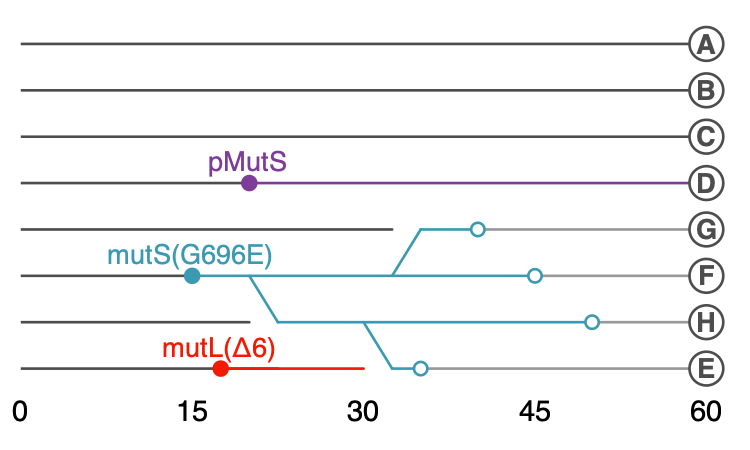

In [4]:
size(1.5, 2.5)

subpops = pops %>% filter(!pop %in% c('X','Y','Z'))

lineages %>% 
    ggplot() + aes(
        x = start*2.5, xend = end*2.5, 
        y = r, yend = rend, 
        col = bg, fill = bg, group = bg) +

    scale_color_manual(values = c('none'=wt_color, 'reverted'='grey60', 'pMutS'=discrete_pal[2], 'mutS(G696E)'=pal[1], 'mutL(Δ6)'=pal[5])) +
    scale_fill_manual(values = c('none'=wt_color, 'reverted'='grey60', 'pMutS'=discrete_pal[2], 'mutS(G696E)'=pal[1], 'mutL(Δ6)'=pal[5])) +

    scale_x_continuous(breaks = seq(0, 60, 15)) +
    coord_cartesian(xlim = c(0,62), ylim = c(0.5, 8.5), expand = c(0,0)) +

    theme(
        axis.line = eb, axis.ticks = eb, axis.text.y = eb, axis.title.y = eb, panel.grid = eb, 
        axis.text.x = element_text(size=7),
        #axis.title.x = element_text(size=28, family='Ubuntu Mono'),
        axis.title.x = eb
         ) +
    nl +

    geom_segment(lwd=lwd, lineend = 'round') +

    # Transfer time change
    # annotate(geom = 'segment', x = 19, xend = 19, y = 0, yend = 8.35, lty = 2, lwd = 0.3, col = 'grey40') +
    # add_text(19, 8.4, '2h/transfer', size = text_size, vjust = 0, col = 'grey40', fontface = 'plain') +

    # Mutator labels
    geom_point(
        data = mutators, size = ps
    ) +
    geom_text(
        data = mutators, aes(label = bg),
        hjust = 0.5, vjust = 0, size = text_size, fontface = text_weight,
        nudge_x = -0.15, nudge_y = 0.25
    ) +

    # Population labels
    geom_point(
        data = subpops, pch = 21, fill = w, col = wt_color, stroke = lwd*1.5, size = pop_circle_size
    ) +
    geom_text(
        data = subpops, aes(label = pop), fill = w, col = wt_color, size = text_size,
        fontface = 'bold'
    ) +

    # Reversions
    geom_point(
        data = reversions, pch = 21, fill = 'white', stroke = lwd*1.5, size = ps
    ) +

    xlab('Generations (×1000)')

psave('Plots/experiment_overview')